In [1]:
import numpy as np, matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy import wcs
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.modeling import models, fitting
from scipy.interpolate import RectBivariateSpline as rbs
from casatasks import *

In [2]:
# NVSS catalog

from dsacalib.preprocess import read_nvss_catalog
import pandas as pd
pd.options.mode.chained_assignment = None
df = read_nvss_catalog()
ras = df.loc[:,'ra']; decs = df.loc[:,'dec']
coords = SkyCoord(ras,decs,frame='icrs',unit='deg')
maj = df.loc[:,'major_axis']; flux = df.loc[:,'flux_20_cm']

In [3]:
# to fit a source position

def fit_src(image,ira,idec,plot=True,nside=100,method='gaus',myvmin=-0.001,myvmax=0.1):
    
    
    nont = int(nside/2)
    mydata = image[idec-nont:idec+nont,ira-nont:ira+nont]
    
    if idec-nont<0:
        return None
    if idec+nont>=image.shape[0]:
        return None
    if ira-nont<0:
        return None
    if ira+nont>=image.shape[0]:
        return None
    
    if not mydata[nont,nont] > 0.:
        return None
    
    
    if method=='gaus':
    
        gaus = models.Gaussian2D(amplitude=0.03,
                                 x_mean=0.,
                                 y_mean=0.,
                                 x_stddev=3.0,
                                 y_stddev=3.0,
                                 theta=np.pi/2.)
    
        y, x = np.mgrid[:nside, :nside]
        y = y.astype(np.float64)
        x = x.astype(np.float64)
        y -= nside/2.+0.5
        x -= nside/2.+0.5
        fit = fitting.LevMarLSQFitter()
        p = fit(gaus, x, y, mydata)
    
        print(p.amplitude.value,p.x_mean.value,p.y_mean.value)
    
        if plot:
            plt.figure(figsize=(10,5))
        
            plt.subplot(1,2,1)
            plt.imshow(mydata,vmin=-0.001,vmax=0.1,origin='lower')
            plt.title('Data')
        
            plt.subplot(1,2,2)
            plt.imshow(mydata-p(x,y),vmin=-0.001,vmax=0.1,origin='lower')
            plt.title('Residual')
        
            plt.show()
        
        return p.amplitude.value,p.y_mean.value,p.x_mean.value
    
    if method=='interp':
        
        x = np.arange(nside)-(nside/2.+0.5)
        y = np.arange(nside)-(nside/2.+0.5)
        p = rbs(x,y,mydata)
        
        manyx = np.linspace(np.min(x),np.max(x),nside*20)
        manyy = np.linspace(np.min(y),np.max(y),nside*20)
        
        interps = p(manyx,manyy)
        wrs = np.where(interps==np.max(interps))
        
        x_mean = manyx[wrs[0]]
        y_mean = manyy[wrs[1]]
        amp = np.max(interps)
                
        if plot:
            plt.figure(figsize=(5,5))
        
            plt.imshow(mydata,origin='lower',vmin=myvmin,vmax=myvmax,extent=[np.min(x),np.max(x),np.min(y),np.max(y)])
            plt.plot([y_mean],[x_mean],'kx')
            plt.title('Data')
        
            plt.show()
            
        return(amp,x_mean,y_mean)
        
        
        

In [4]:
# to fit in RA and DEC
from scipy.optimize import minimize

def line_model(pars, x):

    return pars[0] * np.array(x) + pars[1]

class StraightLineModel(object):
    def __init__(self, x, y, y_err):
        """
        We store the data as attributes of the object so we don't have to
        keep passing it in to the methods that compute the probabilities.
        """
        self.x = np.asarray(x)
        self.y = np.asarray(y)
        self.y_err = np.asarray(y_err)

    def ln_likelihood(self, pars):
        """
        We don't need to pass in the data because we can access it from the
        attributes. This is basically the same as the weighted squared
        deviation function, but includes the constant normalizations for the
        Gaussian likelihood.
        """
        N = len(self.y)
        dy = self.y - line_model(pars, self.x)
        ivar = 1 / self.y_err**2  # inverse-variance
        return -0.5 * (
            N * np.log(2 * np.pi)
            + np.sum(2 * np.log(self.y_err))
            + np.sum(dy**2 * ivar)
        )

    def ln_prior(self, pars):
        """
        The prior only depends on the parameters, so we don't need to touch
        the data at all. We're going to implement a flat (uniform) prior
        over the ranges:
            a : [0, 100]
            b : [-50, 50]

        """

        a, b = pars  # unpack parameters
        ln_prior_val = 0.0  # we'll add to this

        if a < 0 or a > 100.0:
            return -np.inf
        else:
            ln_prior_val += np.log(1e-2)  # normalization, log(1/100)

        if b < -50 or b > 50.0:
            return -np.inf
        else:
            ln_prior_val += np.log(1e-2)  # normalization, log(1/100)

        return ln_prior_val

    def ln_posterior(self, pars):
        """
        Up to a normalization constant, the log of the posterior pdf is just
        the sum of the log likelihood plus the log prior.
        """
        lnp = self.ln_prior(pars)
        if np.isinf(
            lnp
        ):  # short-circuit if the prior is infinite (don't bother computing likelihood)
            return lnp

        lnL = self.ln_likelihood(pars)
        lnprob = lnp + lnL

        if np.isnan(lnprob):
            return -np.inf

        return lnprob

    def __call__(self, pars):
        return self.ln_posterior(pars)


class StraightLineIntrinsicScatterModel(StraightLineModel):
    def ln_prior(self, pars):
        """The prior only depends on the parameters"""

        a, b, lnV = pars

        # flat priors on a, b, lnV
        if a < -2 or a > 2 or b < -10.0 or b > 10.0 or lnV < -2.0 or lnV > 2.0:
            return -np.inf

        # this is only valid up to a numerical constant
        return 0.0

    def ln_likelihood(self, pars):
        """The likelihood function evaluation requires a particular set of model parameters and the data"""
        a, b, lnV = pars
        V = np.exp(lnV)

        N = len(self.y)
        dy = self.y - line_model([a, b], self.x)
        ivar = 1 / (
            self.y_err**2 + V
        )  # inverse-variance now includes intrinsic scatter
        return -0.5 * (
            N * np.log(2 * np.pi) - np.sum(np.log(ivar)) + np.sum(dy**2 * ivar)
        )


## Setup full ms

In [53]:
import os

trigname = '240204aace'
odir = f'/dataz/dsa110/localization_processing/{trigname}'

# calibrate full ms
full_ms = f"{odir}/voltage.ms"
applycal(vis=full_ms,gaintable=[f"{odir}/cal.B0"])

# find phase center
a = listobs(full_ms)
ra = a['field_0']['direction']['m0']['value']
if ra<0.:
    ra += 2.*np.pi
dec = a['field_0']['direction']['m1']['value']
pos = SkyCoord([ra*180./np.pi],[dec*180./np.pi],unit=(u.deg,u.deg))

print(pos.to_string('hmsdms'))

['22h01m55.31100499s +71d29m01.26547087s']


## Derive corrections from VLBI

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2017+7440-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2252+7043-dirty.fits


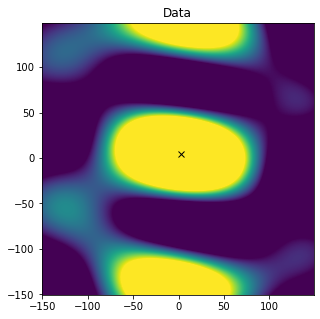

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2312+7241-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2119+7110-dirty.fits


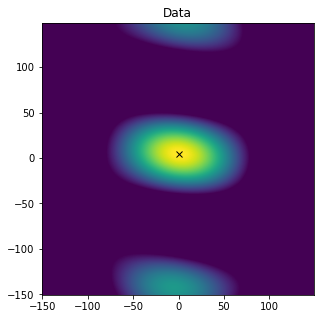

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2059+7328-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2203+7151-dirty.fits


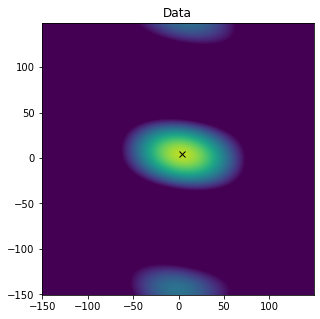

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2203+7029-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2239+7203-dirty.fits


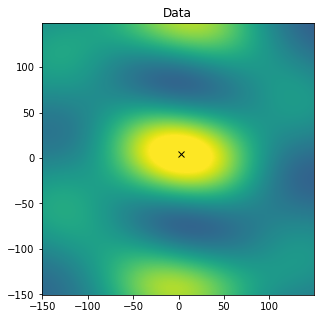

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2248+7054-dirty.fits


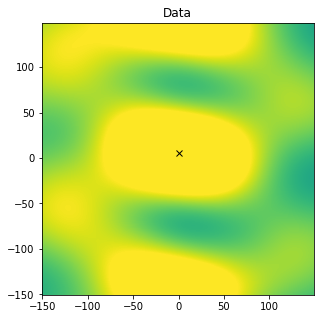

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2132+7240-dirty.fits


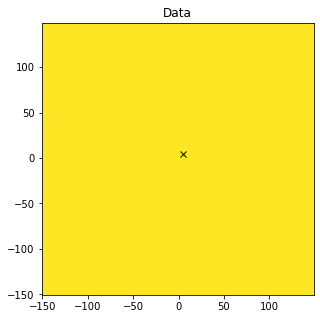

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2258+7114-dirty.fits


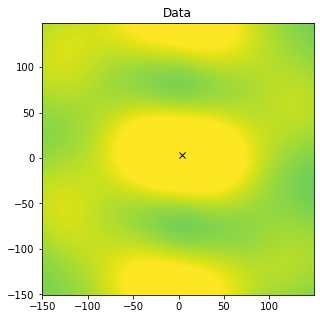

/dataz/dsa110/localization_processing/240204aace/icrs_image/J2300+7110-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2057+7150-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2105+7241-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2250+7129-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2037+7226-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2329+7142-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2142+7056-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2242+7049-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2332+7203-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2145+7114-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2048+7320-dirty.fits
/dataz/dsa110/localization_processing/240204aace/icrs_image/J2222+7220-dirty.fits
/dataz/dsa110/lo

In [54]:
# guess at FRB position from frb image
idict = np.load(odir+"/rfc_idict_more.npz",allow_pickle=True)['idict'].item()

filenames = []
for i,n in enumerate(idict["jname"]):
    filenames.append(odir+"/icrs_image/"+n+"-dirty.fits")
posses = idict['position']
fluxes = idict['flux']

mypixlt = 30.

# get pixel coords

famp = np.zeros(len(posses))
fra = np.zeros(len(posses))
fdec = np.zeros(len(posses))
myx = np.zeros(len(posses))
myflux = np.zeros(len(posses))

for i,f in enumerate(filenames):
    
    try:
    
        print(f)
        d = fits.open(f)
        image = d[0].data[0,0,:,:]
        w = WCS(d[0].header)
    
        world_coords = np.zeros((1,4))
        world_coords[0,0] = posses[i].ra.value
        world_coords[0,1] = posses[i].dec.value
        world_coords[0,3] = 1.
        world_coords[0,2] = 1.405e9
        pix_coords = w.wcs_world2pix(world_coords,0)
        rapix = np.floor(pix_coords[:,0]).astype('int')[0]
        depix = np.floor(pix_coords[:,1]).astype('int')[0]

        pp = fit_src(image,rapix,depix,nside=300,method='interp')
        
        if pp is not None:
            flamp,fx,fy = pp
            famp[i] = flamp
            fra[i] = -fy[0]
            fdec[i] = fx[0]
            myx[i] = posses[i].ra.deg
            myflux[i] = fluxes[i]
            
        if np.sqrt(fx[0]**2.+fy[0]**2.)>mypixlt:
            famp[i] = np.nan
            fra[i] = np.nan
            fdec[i] = np.nan
            myx[i] = np.nan
            myflux[i] = np.nan
            print("FLAGGING THE ABOVE")
                
    except:
        famp[i] = np.nan
        fra[i] = np.nan
        fdec[i] = np.nan
        myx[i] = np.nan
        myflux[i] = np.nan
        


In [55]:
# clean up data, and fit

scl = 0.2
fluxlt = 0.01
fx = scl*fra[famp>fluxlt]
fy = scl*fdec[famp>fluxlt]
mmyx = myx[famp>fluxlt]
mmyflux = myflux[famp>fluxlt]
frbx = pos.ra.deg

ylt = 5.
fx[np.abs(fx-np.median(fx))>ylt] = np.nan
fy[np.abs(fy-np.median(fy))>ylt] = np.nan
fx[np.isnan(fy)] = np.nan
fy[np.isnan(fx)] = np.nan
mmyx[np.isnan(fy)] = np.nan
mmyflux[np.isnan(fy)] = np.nan

fx = fx[~np.isnan(fx)]
fy = fy[~np.isnan(fy)]
mmyx = mmyx[~np.isnan(mmyx)]
mmyflux = mmyflux[~np.isnan(mmyflux)]
mmyerr = 0.45*25./(1000.*mmyflux)

scatter_model_x = StraightLineIntrinsicScatterModel(mmyx,fx,mmyerr)
x0 = [0.01, 0., 0.]  # starting guess for the optimizer
result_ml_scatter_x = minimize(
    lambda *args: -scatter_model_x.ln_likelihood(*args), x0=x0, method="BFGS"
)
print(result_ml_scatter_x)

scatter_model_y = StraightLineIntrinsicScatterModel(mmyx,fy,mmyerr)
x0 = [0.01, 0., 0.]  # starting guess for the optimizer
result_ml_scatter_y = minimize(
    lambda *args: -scatter_model_y.ln_likelihood(*args), x0=x0, method="BFGS"
)
print(result_ml_scatter_y)

      fun: 1.595623157763062
 hess_inv: array([[ 1.44242714e-04, -4.82564375e-02,  3.03208679e-04],
       [-4.82564375e-02,  1.61574092e+01, -1.05878296e-01],
       [ 3.03208679e-04, -1.05878296e-01,  3.86791037e-01]])
      jac: array([-7.55713433e-01, -2.38105655e-03, -4.45514917e-04])
  message: 'Desired error not necessarily achieved due to precision loss.'
     nfev: 236
      nit: 14
     njev: 56
   status: 2
  success: False
        x: array([ 1.30058405e-04, -5.65108957e-01, -2.54718710e+00])
      fun: -6.3724617865533055
 hess_inv: array([[ 6.65850345e-06, -2.25063555e-03,  2.59509155e-10],
       [-2.25063555e-03,  7.61160382e-01, -9.15800532e-08],
       [ 2.59509155e-10, -9.15800532e-08,  2.40754962e-01]])
      jac: array([-2.00569630e-03, -5.24520874e-06,  5.96046448e-08])
  message: 'Desired error not necessarily achieved due to precision loss.'
     nfev: 200
      nit: 32
     njev: 50
   status: 2
  success: False
        x: array([ 2.46599454e-03,  1.16357954e-01

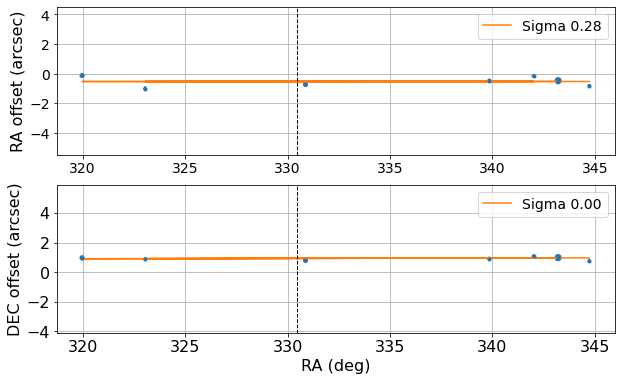

RA offset (arcsec): [-0.52212719]
DEC offset (arcsec): [0.93132097]


In [56]:
plt.figure(figsize=(10,6))
plt.subplot(211)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)

plt.ylabel("RA offset (arcsec)",fontsize=16)
plt.scatter(mmyx,fx,s=mmyflux/0.01)
plt.errorbar(mmyx,fx,fmt='.',yerr=mmyerr)
plt.plot(mmyx,line_model(result_ml_scatter_x.x[:2], mmyx),'-',label=f'Sigma {np.sqrt(np.exp(result_ml_scatter_x.x[2])):.2f}')

plt.ylim(np.median(fx)-ylt,np.median(fx)+ylt)
plt.plot([frbx,frbx],[np.median(fx)-ylt,np.median(fx)+ylt],'k--',lw=1.)
plt.legend(fontsize=14)
plt.grid()

plt.subplot(212)
plt.xlabel("RA (deg)",fontsize=16)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)

plt.ylabel("DEC offset (arcsec)",fontsize=16)
plt.ylim(np.median(fy)-ylt,np.median(fy)+ylt)
plt.scatter(mmyx,fy,s=mmyflux/0.01)
plt.errorbar(mmyx,fy,fmt='.',yerr=mmyerr)
plt.plot(mmyx,line_model(result_ml_scatter_y.x[:2], mmyx),'-',label=f'Sigma {np.sqrt(np.exp(result_ml_scatter_y.x[2])):.2f}')
plt.plot([frbx,frbx],[np.median(fy)-ylt,np.median(fy)+ylt],'k--',lw=1.)
plt.legend(fontsize=14)
plt.grid()

plt.show()

print("RA offset (arcsec):",line_model(result_ml_scatter_x.x[:2], frbx))
print("DEC offset (arcsec):",line_model(result_ml_scatter_y.x[:2], frbx))

myoffset_ra = u.arcsec*line_model(result_ml_scatter_x.x[:2], frbx)
myoffset_dec = u.arcsec*line_model(result_ml_scatter_y.x[:2], frbx)


vlbi_raoff =  fx - line_model(result_ml_scatter_x.x[:2], mmyx)
vlbi_decoff = fy - line_model(result_ml_scatter_y.x[:2], mmyx)

## Image brightest sources in full ms

In [57]:
# find list of NVSS sources
flux_lt = 400.
maj_lt = 35.0
rad_lt = 2.0

idx, d2d, d3d = coords.match_to_catalog_sky(pos)
wrs = np.where((flux>flux_lt) & (maj<maj_lt) & (d2d.deg<rad_lt))[0]
ccoords = coords[wrs]
fflux2 = flux[wrs]
mmaj = maj[wrs]

# image each NVSS source

for i in np.arange(len(fflux2)):
    
    print(f"Imaging source {i+1} of {len(fflux2)} at {ccoords[i].to_string('hmsdms')} with flux {fflux2[i]}")
    os.system(f"rm -rf {odir}/image/im_{i}*")
    output = f"{odir}/image/im_{i}"
    tclean(vis=full_ms,imagename=output,uvrange=">0.2klambda",
           imsize=[1000,1000],cell=['0.3arcsec','0.3arcsec'],weighting='briggs',robust=0.5,
           niter=0,pblimit=0.2,interactive=False,phasecenter=f"J2000 {ccoords[i].to_string('hmsdms')}")
    exportfits(imagename=f"{output}.image",fitsimage=f"{output}.fits")
    



Imaging source 1 of 2 at 22h22m12.4000008s +72d20m43.400004s with flux 751.5



0%....10....20....30....40....50....60....70....80....90....100%
2024-07-11 16:45:38	WARN	tclean::::casa	Warning! Non-zero values at the edge of the .pb image can cause unexpected aliasing effects! (found value 0.30758875608444214 at index [997, 0, 0, 0])

0%....10....20....30....40....50....60....70....80....90....100%
2024-07-11 16:45:49	WARN	task_tclean::SIImageStore::restore (file src/code/synthesis/ImagerObjects/SIImageStore.cc, line 2247)	Restoring with an empty model image. Only residuals will be processed to form the output restored image.


Imaging source 2 of 2 at 21h54m55.0300008s +72d51m39.200004s with flux 838.3



0%....10....20....30....40....50....60....70....80....90....100%
2024-07-11 16:46:01	WARN	tclean::::casa	Warning! Non-zero values at the edge of the .pb image can cause unexpected aliasing effects! (found value 0.47058624029159546 at index [0, 0, 0, 0])

0%....10....20....30....40....50....60....70....80....90....100%
2024-07-11 16:46:11	WARN	task_tclean::SIImageStore::restore (file src/code/synthesis/ImagerObjects/SIImageStore.cc, line 2247)	Restoring with an empty model image. Only residuals will be processed to form the output restored image.


## Measure positions of full_ms sources

Set OBSGEO-B to    -0.986523 from OBSGEO-[XYZ].
Set OBSGEO-H to -6377200.288 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


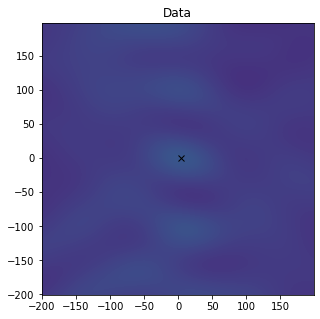

RA: [-1.20391924] arcsec [-0.52212719] arcsec; DEC [-0.11294537] arcsec [0.93132097] arcsec


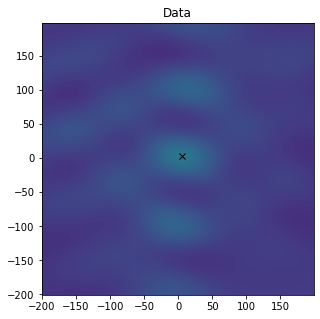

RA: [-1.44334917] arcsec [-0.52212719] arcsec; DEC [0.90463183] arcsec [0.93132097] arcsec


In [58]:
import scipy.stats as sss

pos_fullms = []
snr_fullms = []

for i in np.arange(len(fflux2)):
    
    fl = f"{odir}/image/im_{i}.fits"
    d = fits.open(fl)
    image3 = d[0].data[0,0,:,:]
    w1 = WCS(d[0].header)

    world_coords = np.zeros((1,4))
    world_coords[:,0] = ccoords[i].ra.value
    world_coords[:,1] = ccoords[i].dec.value
    world_coords[:,3] = 1.
    world_coords[:,2] = 1.405e9
    pix_coords = w1.wcs_world2pix(world_coords,0)
    rapix = np.floor(pix_coords[:,0]).astype('int')
    depix = np.floor(pix_coords[:,1]).astype('int')

    for i in np.arange(1):
        
        try:
            famp,myfdec,myfra = fit_src(image3,rapix[i],depix[i],nside=400,method='interp',myvmin=-0.002,myvmax=0.01)
            fra=-0.3*myfra
            fdec = 0.3*myfdec

            new_ra = fra*u.arcsec - myoffset_ra
            new_dec = fdec*u.arcsec - myoffset_dec
            print(f"RA: {fra*u.arcsec} {myoffset_ra}; DEC {fdec*u.arcsec} {myoffset_dec}")
        
            pos_fullms.append([new_ra[0].value,new_dec[0].value])
        
            ffl = np.max(image3)
            mad = sss.median_abs_deviation(image3.ravel())
            snr_fullms.append(ffl/mad)
        except:
            print("Cannot fit")
    

In [59]:
for i in np.arange(len(fflux2)):
    print(f"{pos_fullms[i][0]:.2f} {pos_fullms[i][1]:.2f} {snr_fullms[i]:.2f} {np.sqrt(np.exp(result_ml_scatter_x.x[2])):.2f} {np.sqrt(np.exp(result_ml_scatter_y.x[2])):.2f}")


-0.68 -1.04 7.98 0.28 0.00
-0.92 -0.03 14.05 0.28 0.00
